# Using Alternative Low-Dimensional Embeddings in SpatialZoomer

## Introduction

SpatialZoomer uses non-negative matrix factorization (NMF) as its default dimensionality-reduction method. The non-negative and additive representation produced by NMF facilitates the interpretation of spatial signal diffusion during subsequent spectral graph signal processing.

However, SpatialZoomer is not restricted to NMF. As demonstrated in our study, SpatialZoomer remains robust when alternative low-dimensional representations, including Principal component analysis (PCA), Independent component analysis (ICA), and [scVI](https://github.com/scverse/scvi-tools.git), are used as input.

The embedding used by SpatialZoomer is specified through the `use_rep` parameter of `multiscale_transform()`:

```python
# Compute the desired embedding and store it in `adata.obsm`.
adata.obsm["X_custom"] = X_custom

# Pass the corresponding key to `multiscale_transform(use_rep=...)`.
sz_analyzer.multiscale_transform(
    use_rep="X_custom",
    n_neighbors=20,
    scales=scales,
)
```

This tutorial demonstrates two examples:

* **PCA**, which is directly supported by `sz.performDR`;
* **ICA**, which is computed externally and then passed to SpatialZoomer through the `adata.obsm` embedding interface.

The use of **scVI** embeddings is demonstrated in a separate tutorial `Tutorial3_Alternative_Low_Dimensional_Embeddings_scVI.ipynb`.

Except for the embedding calculation step and the value of `use_rep`, the remaining SpatialZoomer workflow is unchanged.

## Table of Contents

* [0. Data preprocessing](#0-data-preprocessing)
* [1. PCA embedding](#1-pca-embedding)
* [2. ICA embedding](#2-ica-embedding)


## 0. Data preprocessing

This tutorial uses the Xenium Prime mouse brain AnnData object, which can be downloaded from [Google Cloud](https://drive.google.com/file/d/1aGl5zGqxzWD5spzxpDmLPT09VOhu-Ugv/view?usp=drive_link) or from the `Tutorial1_Example_Xenium_Prime_Mouse_Brain` folder on Zenodo repository. The original data can be downloaded from [10x Genomics website](https://www.10xgenomics.com/datasets/xenium-prime-fresh-frozen-mouse-brain).  

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import spatialzoomer as sz
import numpy as np
import scanpy as sc
import seaborn as sns
import os
import matplotlib.pyplot as plt

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 80,     
    "savefig.dpi": 300      
    })
use_dpi = 80 

In [2]:
runLabel = 'Xenium_Prime_Mouse_Brain'
adata_raw = sc.read_h5ad("../Tutorial1_Example_Xenium_Prime_Mouse_Brain/" + runLabel+ "_anndata.h5ad")
adata_raw

AnnData object with n_obs × n_vars = 63173 × 5006
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

<Axes: title={'center': 'Nucleus ratio'}, ylabel='Count'>

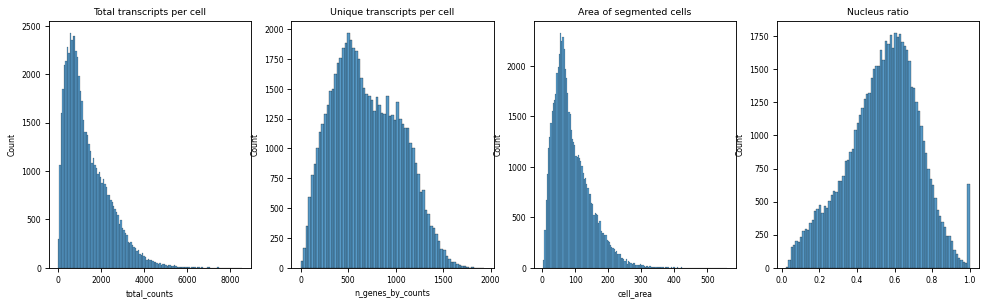

In [3]:
sc.pp.calculate_qc_metrics(adata_raw, percent_top=(10, 20, 50, 150), inplace=True)
fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata_raw.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata_raw.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)


axs[2].set_title("Area of segmented cells")
sns.histplot(
    adata_raw.obs["cell_area"],
    kde=False,
    ax=axs[2],
)

axs[3].set_title("Nucleus ratio")
sns.histplot(
    adata_raw.obs["nucleus_area"] / adata_raw.obs["cell_area"],
    kde=False,
    ax=axs[3],
)

**Quality control and normalization**

* `filter_cells` removes low-quality cells with insufficient transcript and gene detection;
* Cells with missing nuclear area values are removed;
* `filter_genes` removes lowly  detected genes;
* `sz.Preprocess` stores the original count matrix in `adata.layers["counts"]`, performs total-count normalization, and applies a log(1+x) transformation.

In [4]:
# Quality control on cells
sc.pp.filter_cells(adata_raw, min_counts = 10)
sc.pp.filter_cells(adata_raw, min_genes = 5)
adata_raw = adata_raw[~adata_raw.obs['nucleus_area'].isna(), :]

# Quality control on genes
sc.pp.filter_genes(adata_raw, min_cells = 5)

# Normalization
adata_raw = sz.Preprocess(adata_raw)
adata_raw

AnnData object with n_obs × n_vars = 63022 × 5006
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatialdata_attrs', 'log1p'
    obsm: 'spatial'
    layers: 'counts'

## 1. PCA embedding

In [5]:
save_path = './Outputs/' + runLabel+'_PCA_SpatialZoomer/'
if not os.path.exists(save_path):
    os.makedirs(save_path)

adata = adata_raw.copy()

PCA is directly supported by `sz.performDR`.

In [6]:
adata = sz.performDR(adata, type = 'PCA', n_components=50)
adata

Time taken to perform PCA: 21.5266 seconds


AnnData object with n_obs × n_vars = 63022 × 5006
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatialdata_attrs', 'log1p', 'pca'
    obsm: 'spatial', 'X_pca'
    varm: 'PCs'
    layers: 'counts'

Then, set `use_rep="X_pca"` in `sz_analyzer.multiscale_transform()`.

Median similarities:  3.01119131606306
Time taken to construct spatial_knn: 0.4659 seconds
Time taken to perform spectral graph filter bank: 29.0220 seconds
Transformed signals saved to ./Outputs/Xenium_Prime_Mouse_Brain_PCA_SpatialZoomer//Xenium_Prime_Mouse_Brain_transformed_signals.h5


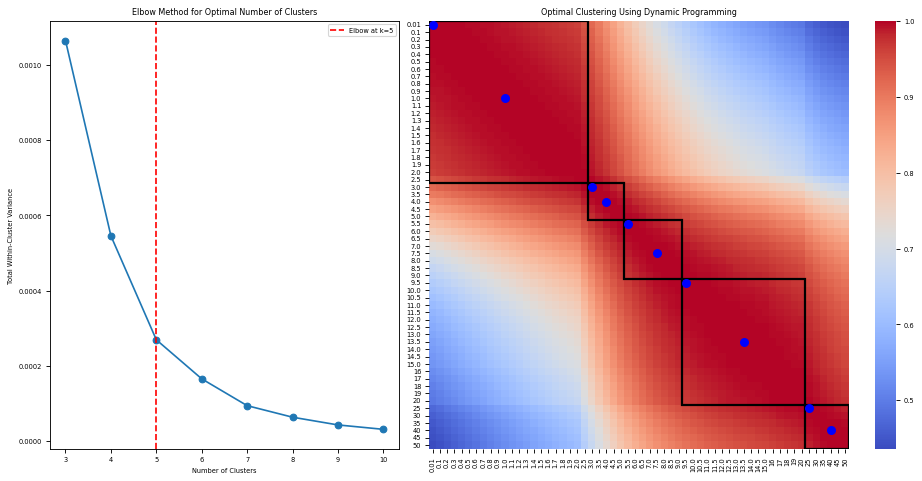

The optimal number of clusters is: 5
Typical scales: [0.01, 1.0, 3.0, 4.0, 5.5, 7.5, 9.5, 13.5, 25, 40]
Time taken to perform identification of typical scales: 7.5462 seconds
Time taken to perform UMAP and clustering for raw signal: 202.2796 seconds
Time taken to perform clustering for signal at scale 1.0: 87.8754 seconds
Time taken to perform clustering for signal at scale 3.0: 87.4269 seconds
Time taken to perform clustering for signal at scale 4.0: 86.5510 seconds
Time taken to perform clustering for signal at scale 5.5: 83.4962 seconds
Time taken to perform clustering for signal at scale 7.5: 85.5768 seconds
Total time: 430.9583 seconds


In [ ]:
sz_analyzer = sz.MultiscaleAnalysis(adata=adata, runLabel=runLabel, save_path=save_path)
 
scales = [0.01] \
    + np.arange(0.1, 2.1, 0.1).tolist() \
    + np.arange(2.5, 15.5, 0.5).tolist() \
    + np.arange(16, 21, 1).tolist() \
    +  np.arange(25, 55, 5).tolist()
scales = [round(x, 2) for x in scales]

sz_analyzer.dpi = use_dpi

# To use the PCA embedding in SpatialZoomer, set:
sz_analyzer.multiscale_transform(use_rep='X_pca', n_neighbors=20, scales=scales, pattern ='None')
sz_analyzer.identify_typical_scales(max_clusters=10, min_clusters=3)

resolutions = [0.8, 1]
sz_analyzer.clustering(n_clusters_kmeans=10000, resolutions=resolutions, min_scale = 0.5, max_scale = 8)
sz_analyzer.adata.write(save_path + runLabel + '_PCA_SpatialZoomer.h5ad')

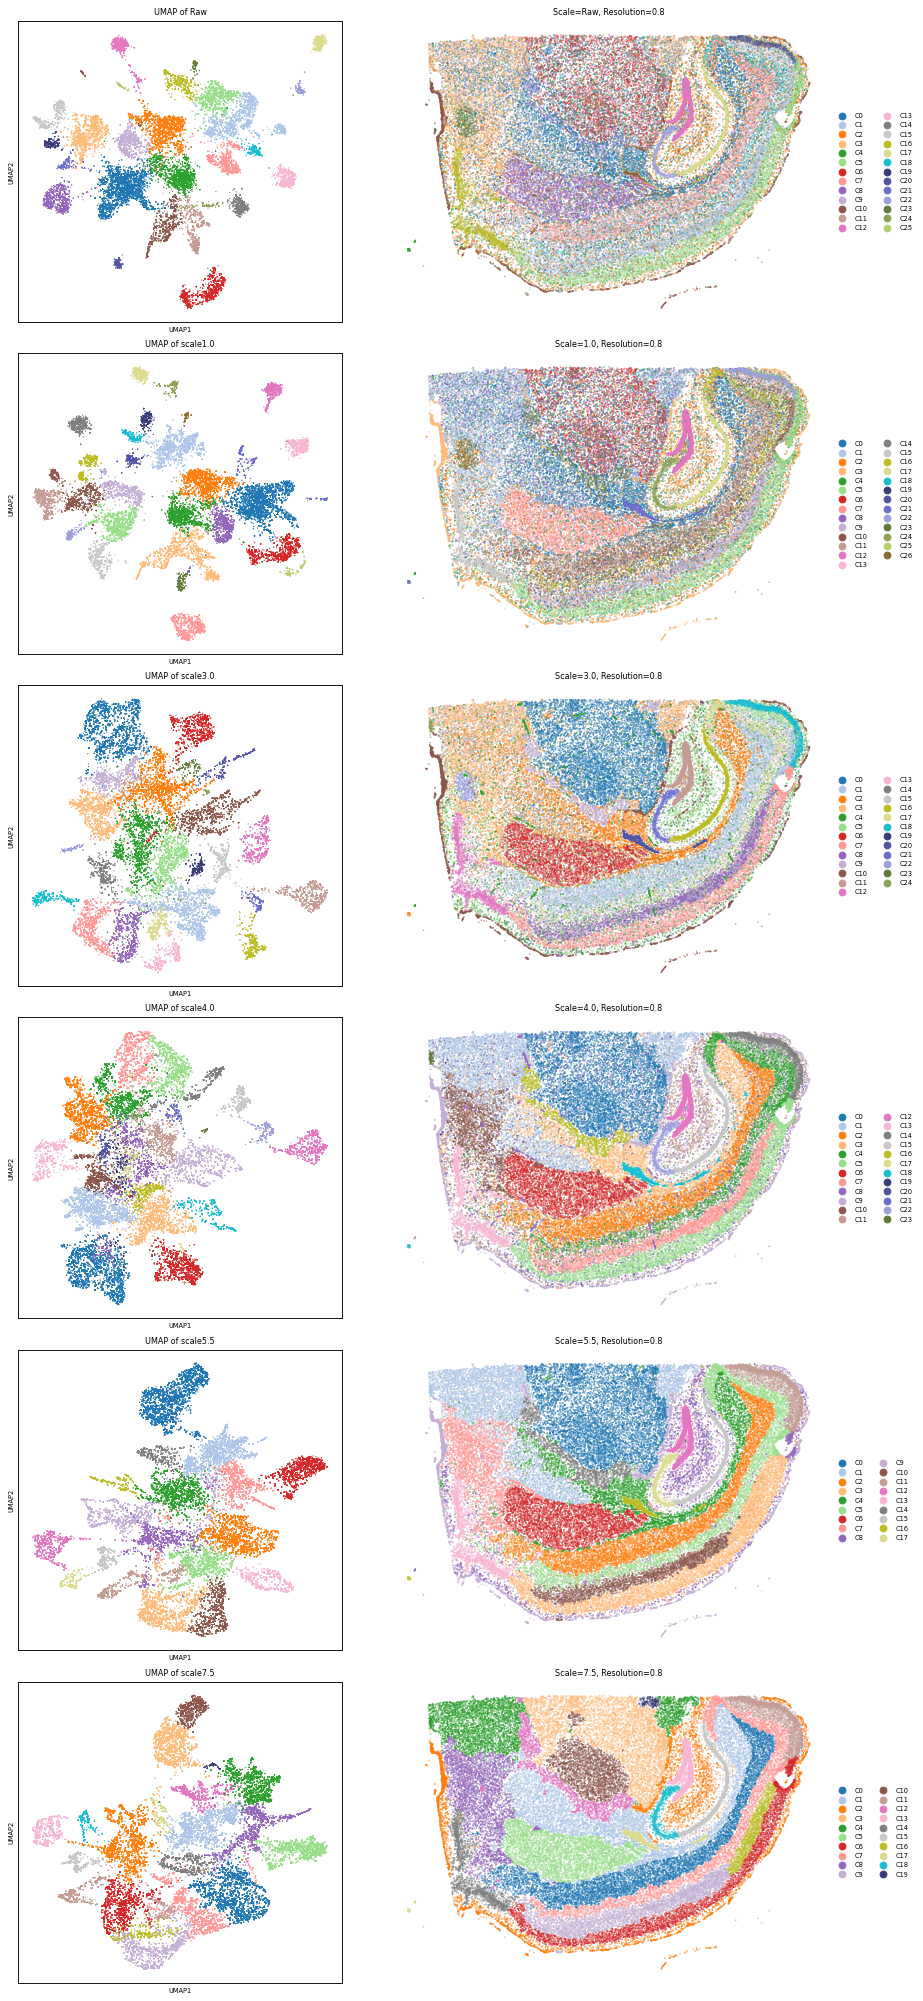

In [8]:
sz_analyzer.plot_multiscale_clusters(resolution=0.8, figsize=(12, 25), pt_size_scatter= 0.1)

## 2. ICA embedding

In [9]:
save_path = './Outputs/' + runLabel+'_ICA_SpatialZoomer/'
if not os.path.exists(save_path):
    os.makedirs(save_path)

adata = adata_raw.copy()

First, calculate the ICA embedding from the gene expression matrix `adata.X` and store it in `adata.obsm["X_ica"]`.

In [10]:
from sklearn.decomposition import FastICA
sc.pp.scale(adata, max_value=10)
n_components = 50
ica = FastICA(
    n_components=n_components,
    random_state=0,
    whiten="unit-variance",
    max_iter=500
)

X_ica = ica.fit_transform(adata.X)
adata.obsm["X_ica"] = X_ica
adata.uns["ica"] = {
    "components": ica.components_,   # shape: (n_components, n_genes)
    "mixing": ica.mixing_
}

Then, set `use_rep="X_ica"` in `sz_analyzer.multiscale_transform()`.

In [ ]:
sz_analyzer = sz.MultiscaleAnalysis(adata=adata, runLabel=runLabel, save_path=save_path)
 
scales = [0.01] \
    + np.arange(0.1, 2.1, 0.1).tolist() \
    + np.arange(2.5, 15.5, 0.5).tolist() \
    + np.arange(16, 21, 1).tolist() \
    +  np.arange(25, 55, 5).tolist()
scales = [round(x, 2) for x in scales]

sz_analyzer.dpi = use_dpi

# To use the ICA embedding in SpatialZoomer, set:
sz_analyzer.multiscale_transform(use_rep='X_ica', n_neighbors=20, scales=scales, pattern ='None')
sz_analyzer.identify_typical_scales(max_clusters=10, min_clusters=3)

resolutions = [0.8, 1]
sz_analyzer.clustering(n_clusters_kmeans=10000, resolutions=resolutions, min_scale = 0.5, max_scale = 8)
sz_analyzer.adata.write(save_path + runLabel + '_ICA_SpatialZoomer.h5ad')

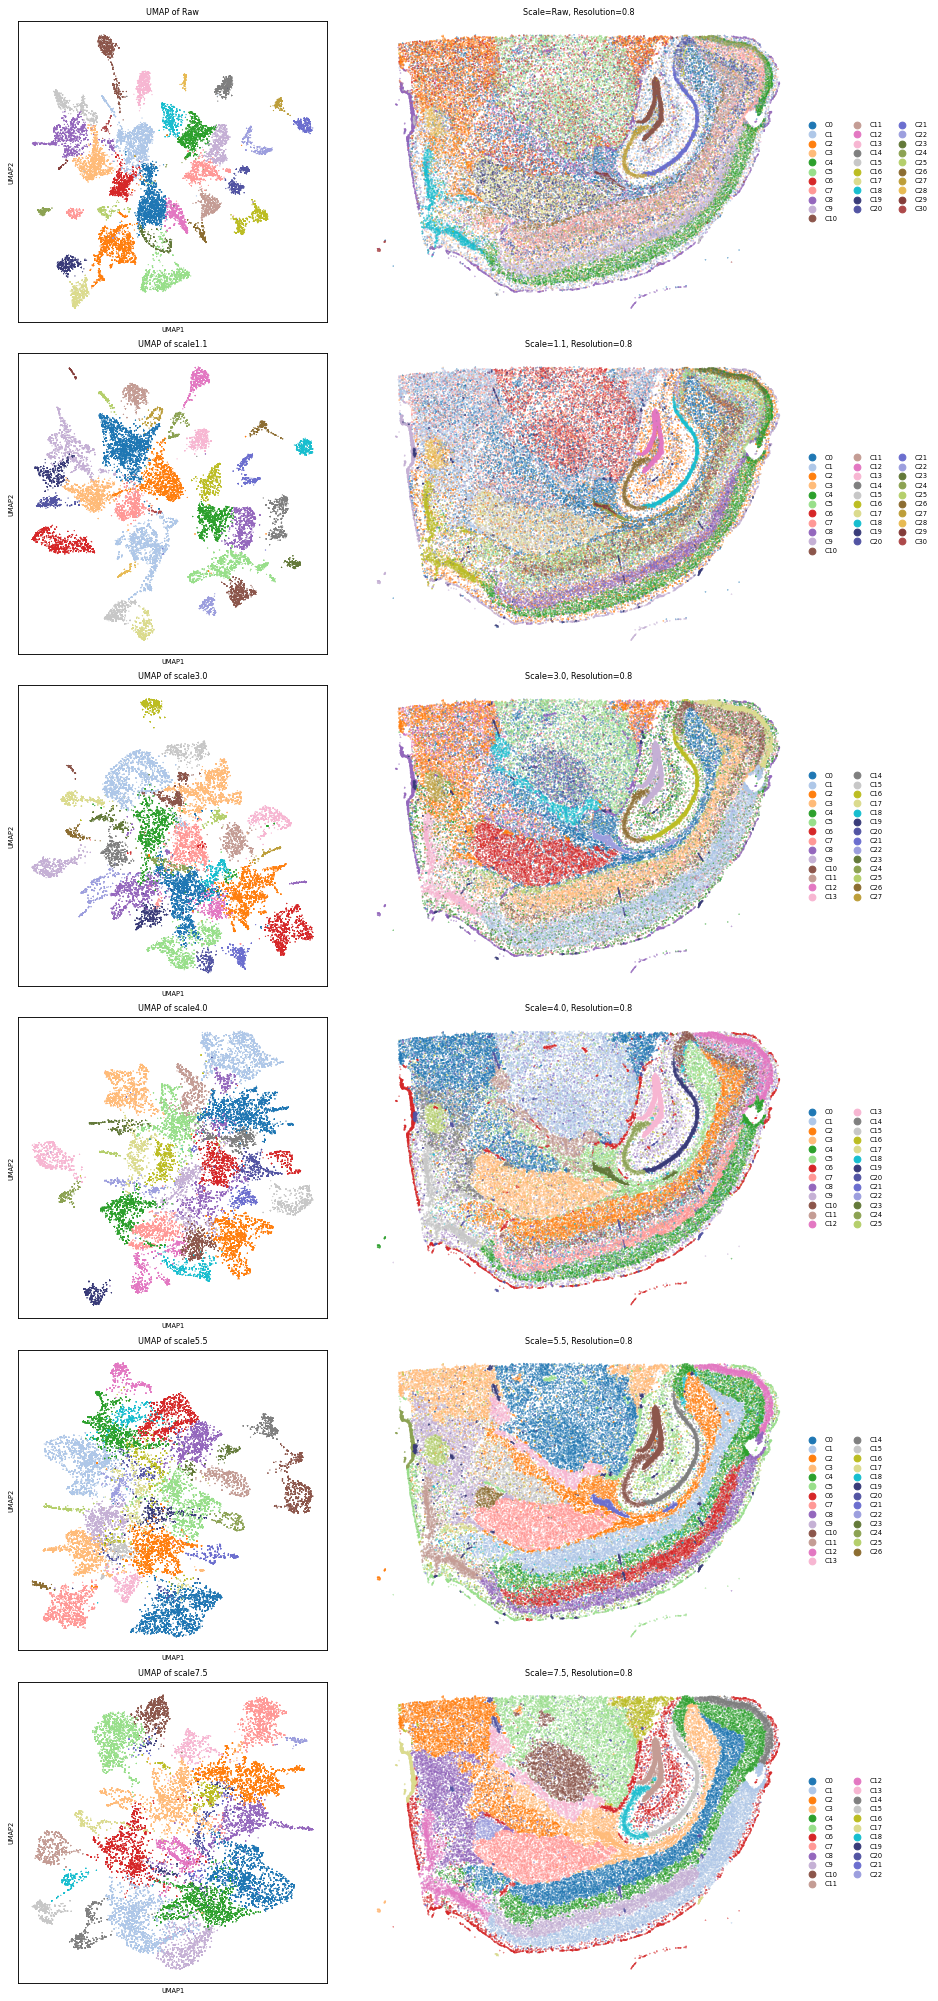

In [12]:
sz_analyzer.plot_multiscale_clusters(resolution=0.8, figsize=(12, 25), pt_size_scatter= 0.1)